# Portfolio research | Public evidence dashboard

This notebook presents **published aggregate research results only**. It uses no securities, model coefficients, research code, or holdings-level records. Results are exploratory and **not evidence of deployable alpha**.

The monthly and quarterly comparisons are separate matched-date cohorts. The return-forecast experiment is a further separate cohort and should not be interpreted as a directly controlled comparison to the portfolio-policy study.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works from a terminal, notebook folder, or project root.
search = [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'equitylab_public']
ROOT = next((p for p in search if (p / 'results' / 'portfolio_policy_summary.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run the notebook from the public repository or its notebooks/ directory.')
RESULTS = ROOT / 'results'
policy = pd.read_csv(RESULTS / 'portfolio_policy_summary.csv')
selection = pd.read_csv(RESULTS / 'selection_and_weighting.csv')
forecast = pd.read_csv(RESULTS / 'forecast_allocation_comparison.csv')
coverage = pd.read_csv(RESULTS / 'historical_panel_coverage.csv', parse_dates=['decision_date'])
solver = pd.read_csv(RESULTS / 'solver_reliability.csv')
for frame in (policy, selection, forecast):
    frame.columns = frame.columns.str.strip()
policy['periods'] = pd.to_numeric(policy['periods'])
for col in ['start','end']:
    policy[col] = pd.to_datetime(policy[col])
print('Data root:', ROOT)
print('Policy records:', len(policy), '| Frequencies:', ', '.join(policy.frequency.unique()))
print('Available portfolio fields:', ', '.join(policy.columns))

Data root: /home/biol0178/projects/EquityLab-public
Policy records: 10 | Frequencies: monthly, quarterly
Available portfolio fields: frequency, model, periods, start, end, ending_wealth, spy_wealth, mean_active, volatility, max_drawdown, mean_turnover, initial_notional


## 1. Matched portfolio benchmark tables

Each frequency is evaluated against SPY on the **same dates within that frequency**. All ending-wealth figures use an initial notional of 10,000. Annualised volatility and drawdown are historical estimates; no risk-free adjustment is inferred.

In [12]:
name_map = {'joint_l2':'Joint L2', 'joint_l1':'Joint L1',
            'joint_elastic_net':'Joint Elastic Net', 'equal_all':'Equal-weight all',
            'equal_top10':'Equal-weight selected 10'}
policy['strategy'] = policy.model.map(name_map).fillna(policy.model)
policy['relative_spy_pct'] = 100 * (policy.ending_wealth / policy.spy_wealth - 1)
policy['max_drawdown_pct'] = 100 * policy.max_drawdown
policy['volatility_pct'] = 100 * policy.volatility
policy['turnover_pct'] = 100 * policy.mean_turnover
for frequency, group in policy.groupby('frequency', sort=False):
    print(f'\n{frequency.upper()} | {group.periods.iloc[0]} matched periods | {group.start.min().date()} to {group.end.max().date()}')
    display(group[['strategy','periods','ending_wealth','spy_wealth','relative_spy_pct',
                   'volatility_pct','max_drawdown_pct','turnover_pct']]
            .sort_values('ending_wealth', ascending=False).round(2).reset_index(drop=True))


MONTHLY | 65 matched periods | 2020-07-31 to 2025-12-31


,strategy,periods,ending_wealth,spy_wealth,relative_spy_pct,volatility_pct,max_drawdown_pct,turnover_pct
0,Joint L2,65,27073.96,20583.5,31.53,17.92,-30.07,23.87
1,Joint Elastic Net,65,25466.08,20583.5,23.72,17.17,-25.57,24.76
2,Joint L1,65,23315.93,20583.5,13.27,17.63,-29.26,28.05
3,Equal-weight all,65,19550.00,20583.5,-5.02,13.96,-19.68,5.92
4,Equal-weight selected 10,65,18260.53,20583.5,-11.29,14.94,-20.37,41.35



QUARTERLY | 9 matched periods | 2023-09-29 to 2025-12-31


,strategy,periods,ending_wealth,spy_wealth,relative_spy_pct,volatility_pct,max_drawdown_pct,turnover_pct
0,Joint Elastic Net,9,20449.50,16597.87,23.21,16.34,-5.07,44.42
1,Joint L2,9,19848.21,16597.87,19.58,13.67,-4.15,53.14
2,Joint L1,9,19531.93,16597.87,17.68,16.19,-5.17,37.96
3,Equal-weight selected 10,9,15706.33,16597.87,-5.37,14.57,-3.06,80.50
4,Equal-weight all,9,14928.73,16597.87,-10.06,7.88,-0.81,19.06


## 2. Matched terminal wealth versus SPY

The SPY line is a benchmark for **the same evaluation window**, not a separate out-of-sample period. Monthly and quarterly figures deliberately appear on separate axes.

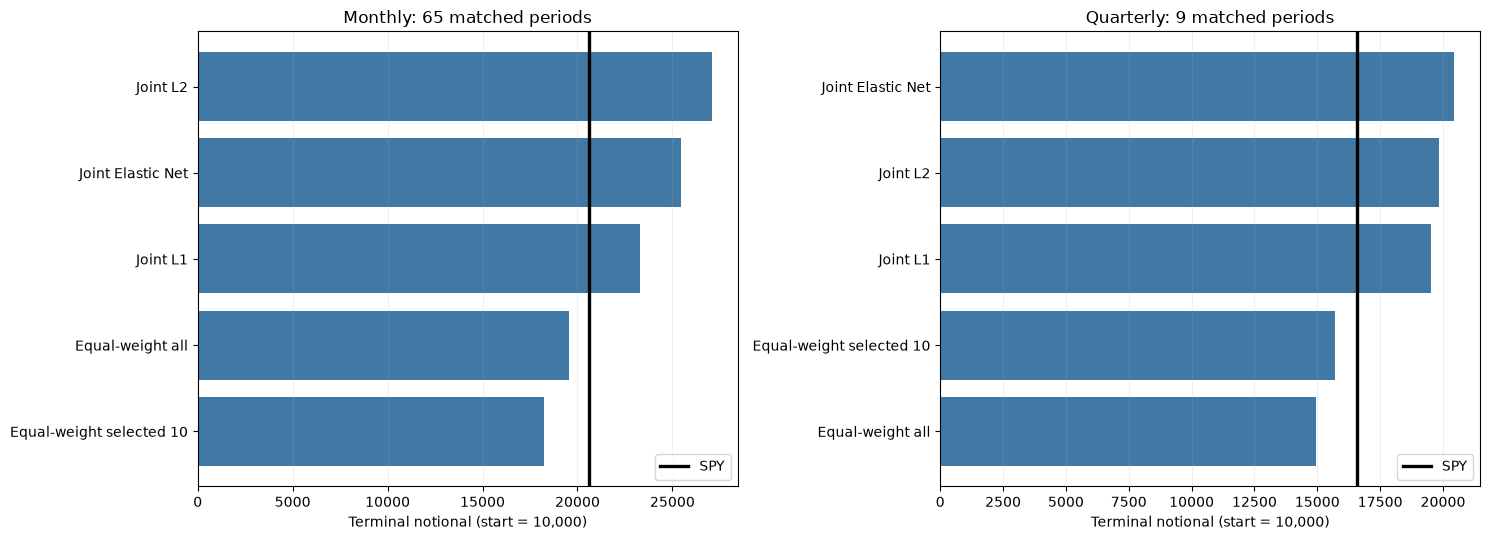

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(15,5.5))
for ax, frequency in zip(axs, ['monthly','quarterly']):
    g = policy[policy.frequency.eq(frequency)].sort_values('ending_wealth')
    ax.barh(g.strategy, g.ending_wealth, color='#4278a4')
    if not g.empty:
        ax.axvline(g.spy_wealth.iloc[0], color='black', linewidth=2.4, label='SPY')
        ax.set_title(f'{frequency.title()}: {int(g.periods.iloc[0])} matched periods')
    ax.set_xlabel('Terminal notional (start = 10,000)')
    ax.legend()
    ax.grid(axis='x', alpha=.2)
fig.tight_layout();plt.show()

## 3. Risk-return and drawdown comparison

These are **summary-level comparisons**, not daily return paths. The annualised volatility and maximum drawdowns come from the saved portfolio reports.

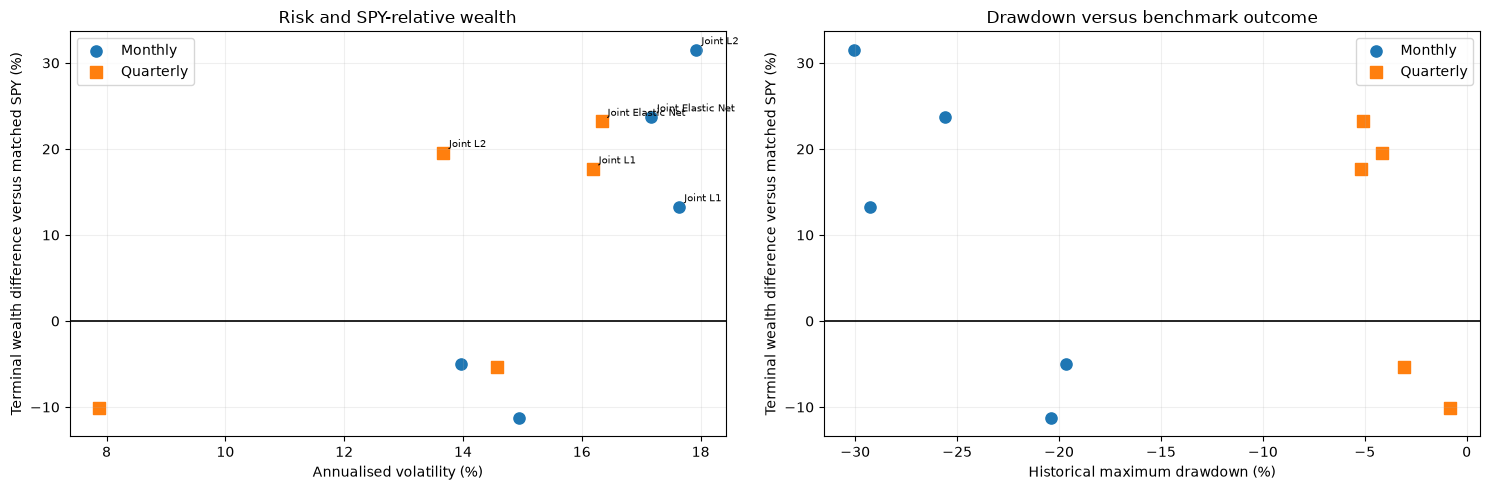

In [14]:
fig,axs=plt.subplots(1,2,figsize=(15,5))
for f,marker in [('monthly','o'),('quarterly','s')]:
    g=policy[policy.frequency.eq(f)]
    axs[0].scatter(g.volatility_pct,g.relative_spy_pct,label=f.title(),s=65,marker=marker)
    for _,r in g.iterrows():
        if r.model.startswith('joint_'): axs[0].annotate(r.strategy,(r.volatility_pct,r.relative_spy_pct),fontsize=7,xytext=(4,4),textcoords='offset points')
axs[0].axhline(0,color='black',linewidth=1.2)
axs[0].set(xlabel='Annualised volatility (%)',ylabel='Terminal wealth difference versus matched SPY (%)',title='Risk and SPY-relative wealth')
axs[0].legend();axs[0].grid(alpha=.2)
for f, marker in [('monthly','o'),('quarterly','s')]:
    g=policy[policy.frequency.eq(f)]
    axs[1].scatter(g.max_drawdown_pct,g.relative_spy_pct,label=f.title(),s=65,marker=marker)
axs[1].axhline(0,color='black',linewidth=1.2)
axs[1].set(xlabel='Historical maximum drawdown (%)',ylabel='Terminal wealth difference versus matched SPY (%)',title='Drawdown versus benchmark outcome')
axs[1].legend();axs[1].grid(alpha=.2)
fig.tight_layout();plt.show()

## 4. Time-related evidence: historical data coverage

This is a genuine dated time series, showing the size of the eligible panel and reported accounting-data coverage over time. It is **not** a strategy wealth curve.

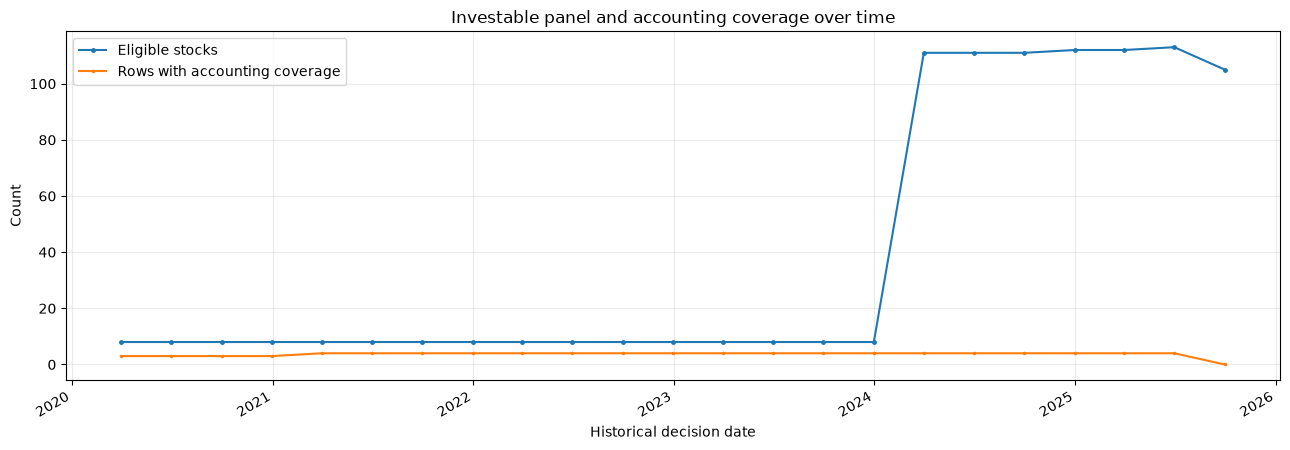

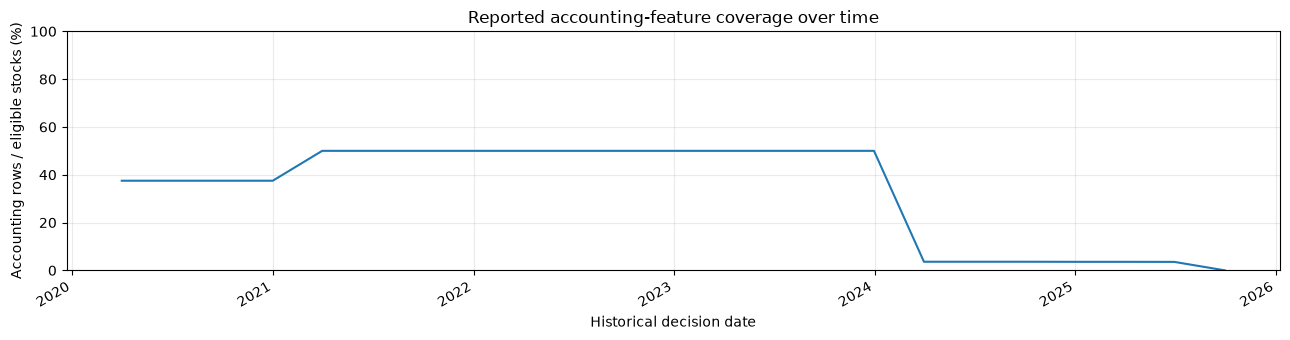

In [15]:
coverage = coverage.sort_values('decision_date').copy()
coverage['accounting_share_pct']=np.where(coverage.panel_stocks.gt(0),100*coverage.accounting_rows/coverage.panel_stocks,np.nan)
fig, ax=plt.subplots(figsize=(13,4.6))
ax.plot(coverage.decision_date,coverage.panel_stocks,marker='o',markersize=2.5,label='Eligible stocks')
ax.plot(coverage.decision_date,coverage.accounting_rows,marker='.',markersize=3,label='Rows with accounting coverage')
ax.set(xlabel='Historical decision date',ylabel='Count',title='Investable panel and accounting coverage over time')
ax.legend();ax.grid(alpha=.25);fig.autofmt_xdate();fig.tight_layout();plt.show()
fig, ax=plt.subplots(figsize=(13,3.5))
ax.plot(coverage.decision_date,coverage.accounting_share_pct)
ax.set(xlabel='Historical decision date',ylabel='Accounting rows / eligible stocks (%)',ylim=(0,100),title='Reported accounting-feature coverage over time')
ax.grid(alpha=.25);fig.autofmt_xdate();fig.tight_layout();plt.show()

## 5. Time-related evidence: cohort evaluation windows

These lines show **when each evaluation cohort starts and ends**, and how many historical decisions are represented. They must not be interpreted as portfolio returns.

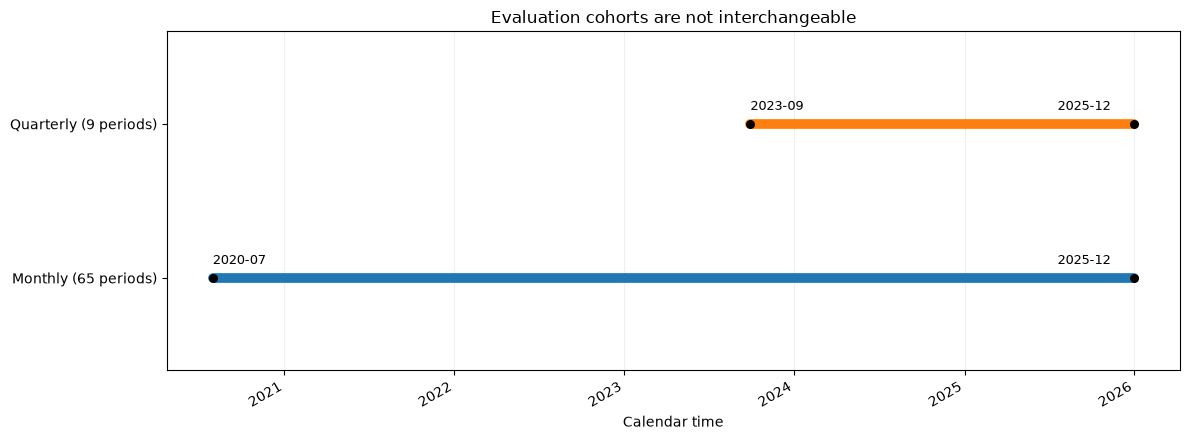

In [16]:
fig,ax=plt.subplots(figsize=(12,4.5))
spans=policy.groupby('frequency',as_index=False).agg(start=('start','min'),end=('end','max'),periods=('periods','first'))
for i,r in spans.iterrows():
    ax.plot([r.start,r.end],[i,i],linewidth=7,solid_capstyle='round',label=f'{r.frequency}: {int(r.periods)} periods')
    ax.scatter([r.start,r.end],[i,i],s=30,color='black',zorder=4)
    ax.annotate(r.start.strftime('%Y-%m'),(r.start,i),xytext=(0,10),textcoords='offset points',fontsize=9)
    ax.annotate(r.end.strftime('%Y-%m'),(r.end,i),xytext=(-55,10),textcoords='offset points',fontsize=9)
ax.set_yticks(range(len(spans)),[f'{r.frequency.title()} ({int(r.periods)} periods)' for _,r in spans.iterrows()])
ax.set(xlabel='Calendar time',title='Evaluation cohorts are not interchangeable',ylim=(-.6,len(spans)-.4))
ax.grid(axis='x',alpha=.2);fig.autofmt_xdate();fig.tight_layout();plt.show()

## 6. Stock selection versus allocation

The equal-weight selected-stock portfolio isolates much of the stock-selection effect. Its advantage relative to the optimised weights is not guaranteed across frequencies.

MONTHLY


,strategy,n_periods,ending_wealth,spy_wealth,sharpe_zero_rf,max_drawdown,mean_turnover
0,Equal-weight all,65,19549.996,20583.496,0.960,-0.197,0.059
1,Joint L2 allocation,65,27073.957,20583.496,1.123,-0.301,0.239
2,"L2-selected top 10, equal-weight",65,30120.523,20583.496,1.173,-0.273,0.348


QUARTERLY


,strategy,n_periods,ending_wealth,spy_wealth,sharpe_zero_rf,max_drawdown,mean_turnover
0,Equal-weight all,9,14928.732,16597.872,2.343,-0.008,0.191
1,Joint L2 allocation,9,19848.212,16597.872,2.373,-0.042,0.531
2,"L2-selected top 10, equal-weight",9,19378.767,16597.872,2.460,-0.024,0.547


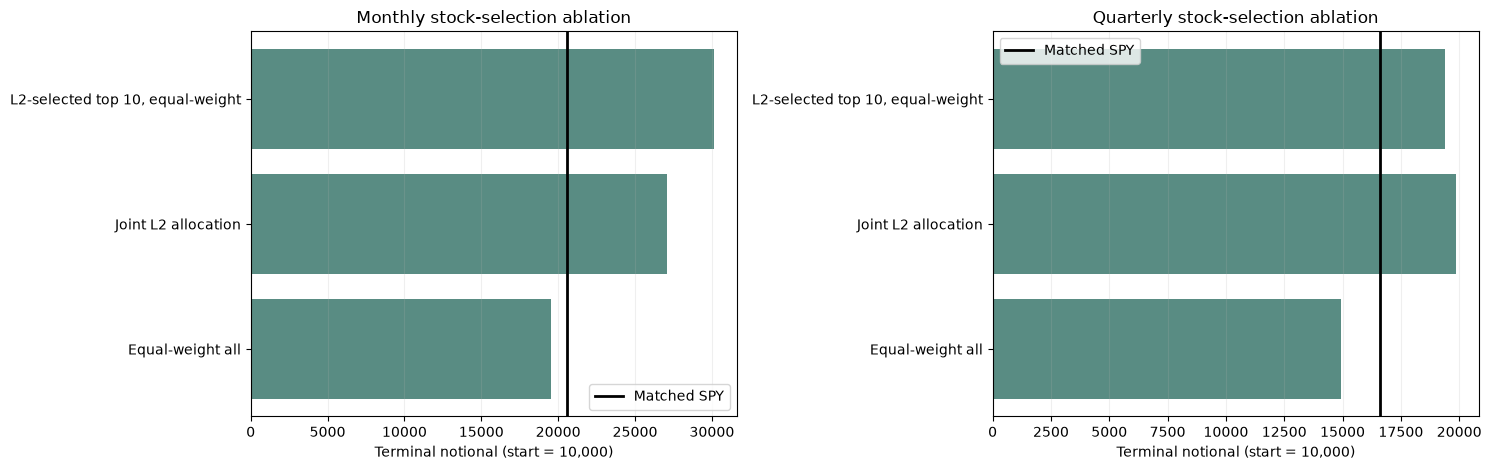

In [17]:
selected=selection[selection.model.isin(['equal_all_replay','joint_l2_alloc_replay','joint_l2_top10_ew'])].copy()
selected['strategy']=selected.model.map({'equal_all_replay':'Equal-weight all','joint_l2_alloc_replay':'Joint L2 allocation','joint_l2_top10_ew':'L2-selected top 10, equal-weight'})
for f,g in selected.groupby('frequency',sort=False):
    print(f.upper())
    display(g[['strategy','n_periods','ending_wealth','spy_wealth','sharpe_zero_rf','max_drawdown','mean_turnover']].round(3).reset_index(drop=True))
fig,axs=plt.subplots(1,2,figsize=(15,4.8))
for ax,f in zip(axs,['monthly','quarterly']):
    g=selected[selected.frequency.eq(f)]
    ax.barh(g.strategy,g.ending_wealth,color='#598c83')
    if not g.empty:ax.axvline(g.spy_wealth.iloc[0],color='black',linewidth=2,label='Matched SPY');ax.legend()
    ax.set(xlabel='Terminal notional (start = 10,000)',title=f'{f.title()} stock-selection ablation')
    ax.grid(axis='x',alpha=.2)
fig.tight_layout();plt.show()

## 8. Optimiser reliability — audit table

The convergence-status data are diagnostics of the solver, **not** evidence of market predictability. Equal-weight baselines have no optimisation convergence status.

,frequency,model,periods,converged,nonconverged,unknown_status
0,monthly,equal_all,65,0,0,65
1,monthly,equal_top10,65,0,0,65
2,monthly,joint_elastic_net,65,65,0,0
3,monthly,joint_l1,65,65,0,0
4,monthly,joint_l2,65,65,0,0
5,quarterly,equal_all,9,0,0,9
6,quarterly,equal_top10,9,0,0,9
7,quarterly,joint_elastic_net,9,9,0,0
8,quarterly,joint_l1,9,9,0,0
9,quarterly,joint_l2,9,9,0,0


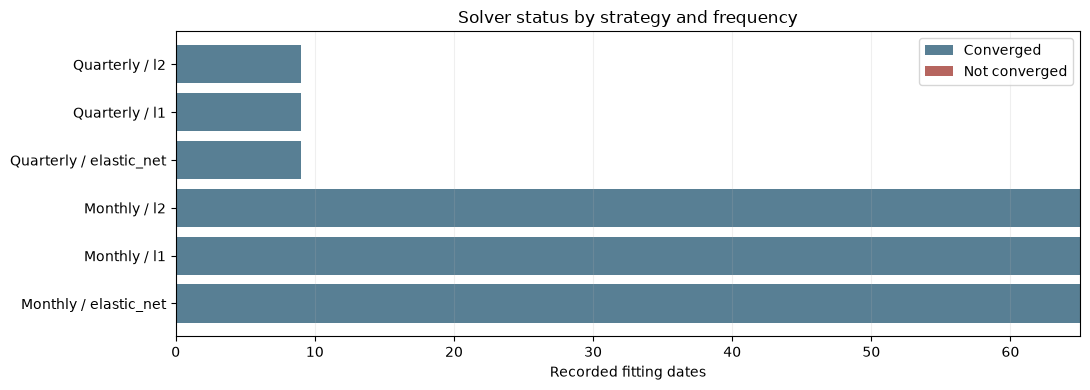

In [18]:
display(solver.sort_values(['frequency','model']).reset_index(drop=True))
models=solver[solver.model.str.startswith('joint_')].copy()
fig,ax=plt.subplots(figsize=(11,4))
models['label']=models.frequency.str.title()+' / '+models.model.str.replace('joint_','',regex=False)
ax.barh(models.label,models.converged,color='#587f94',label='Converged')
ax.barh(models.label,models.nonconverged,left=models.converged,color='#b6655f',label='Not converged')
ax.set(xlabel='Recorded fitting dates',title='Solver status by strategy and frequency')
ax.legend();ax.grid(axis='x',alpha=.2);fig.tight_layout();plt.show()

## 9. Evidence boundaries and reproducibility

- The dated wealth charts shown below are exported images. Public CSV tables contain **aggregates**, not the observations needed to calculate time-varying strategy drawdowns or rolling Sharpe. Such curves are deliberately omitted rather than interpolated or fabricated.
- The time-related charts above use verified **historical coverage dates** and **evaluation date ranges**.
- Different frequencies and study designs should not be ranked as though they share an identical holdout.
- Universe construction, point-in-time information availability, sample size and execution costs limit investment interpretation.
- See `docs/limitations.md`, `docs/evidence_map.md` and `docs/data_sources_and_coverage.md` for scope and caveats.

The notebook intentionally contains no private model implementations or security-level observations.

## Historical wealth trajectories and SPY benchmark

The charts are authentic exported historical results. Different cohorts have different test windows; neither their wealth levels nor their ending values should be compared across cohorts. Dated raw returns, holdings and implementation remain private.


Portfolio policies — monthly


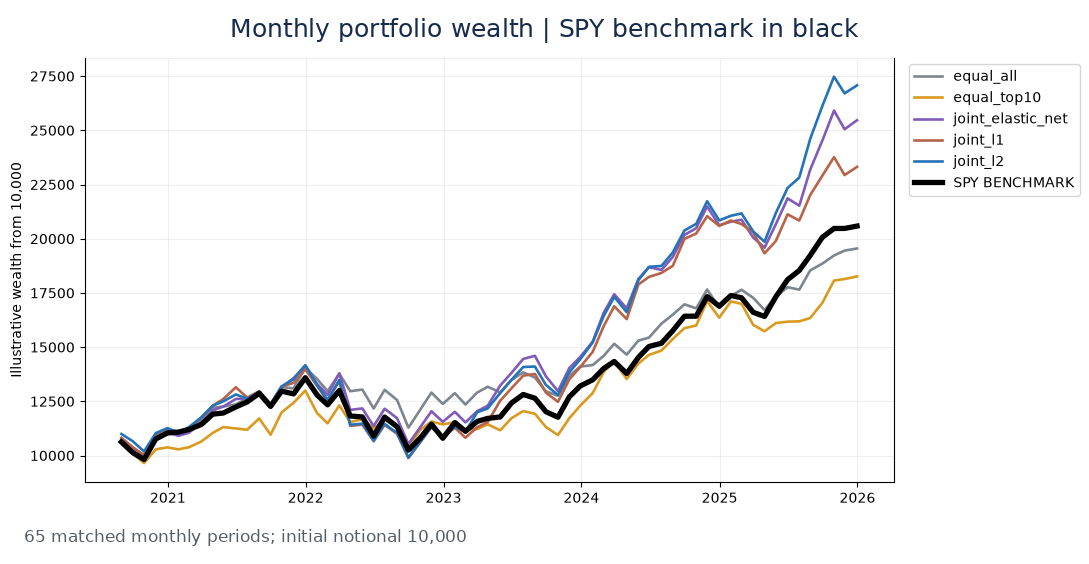

Portfolio policies — quarterly


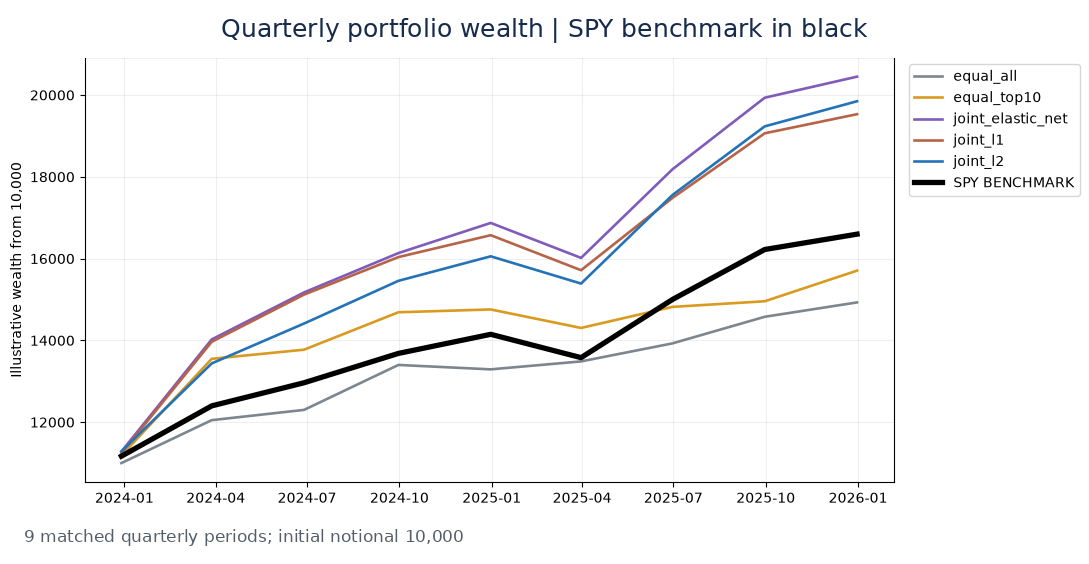

Forecast-informed allocations — monthly


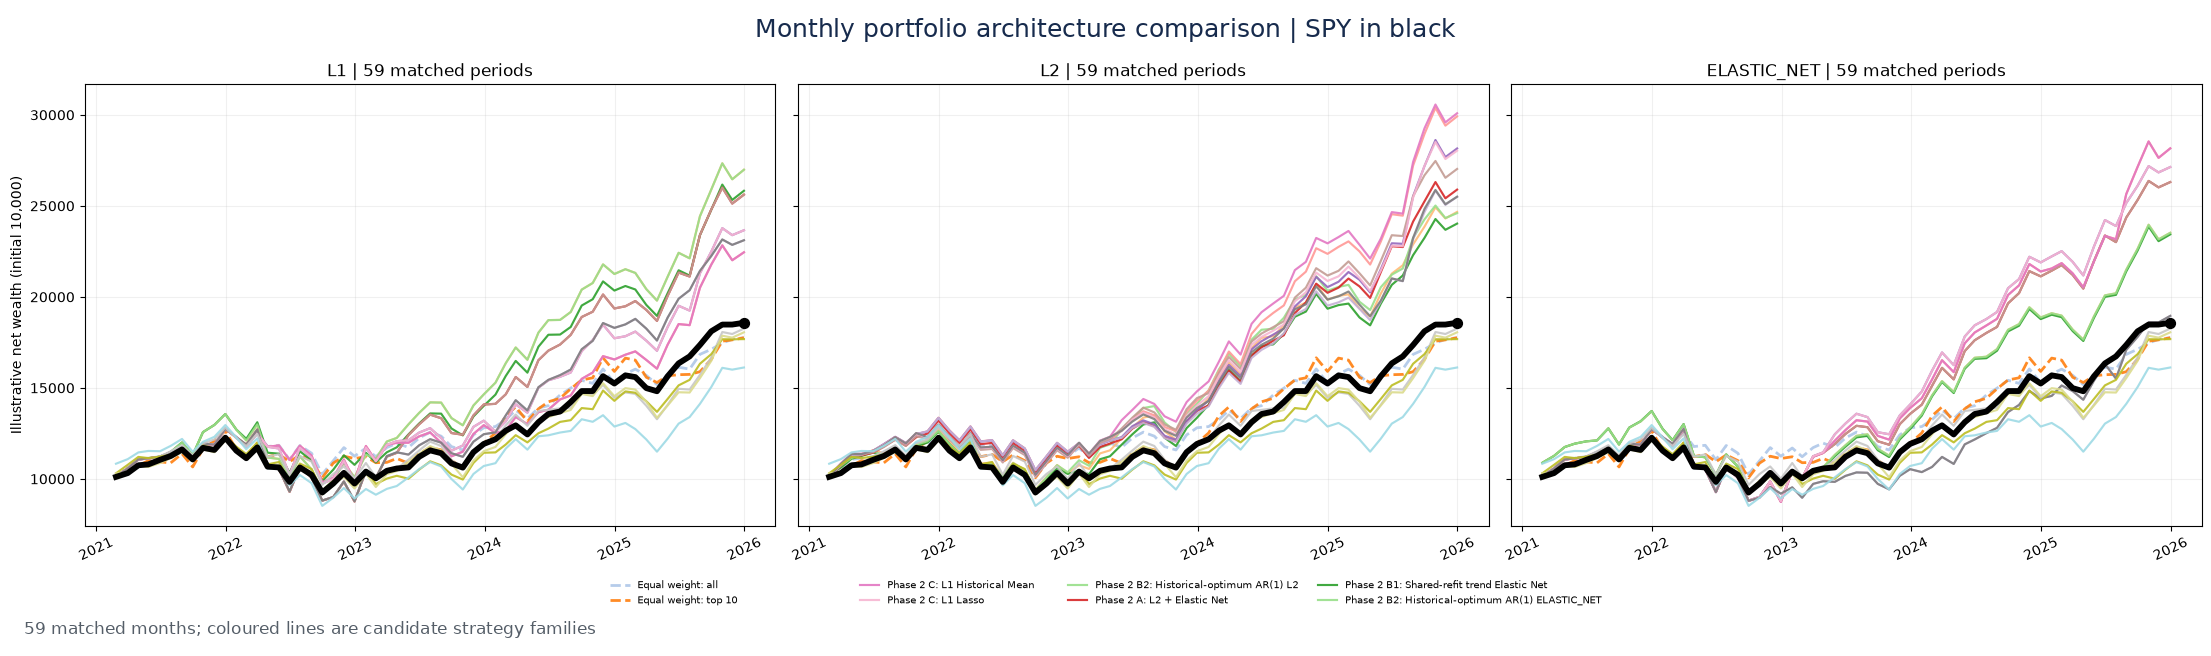

Forecast-informed allocations — quarterly


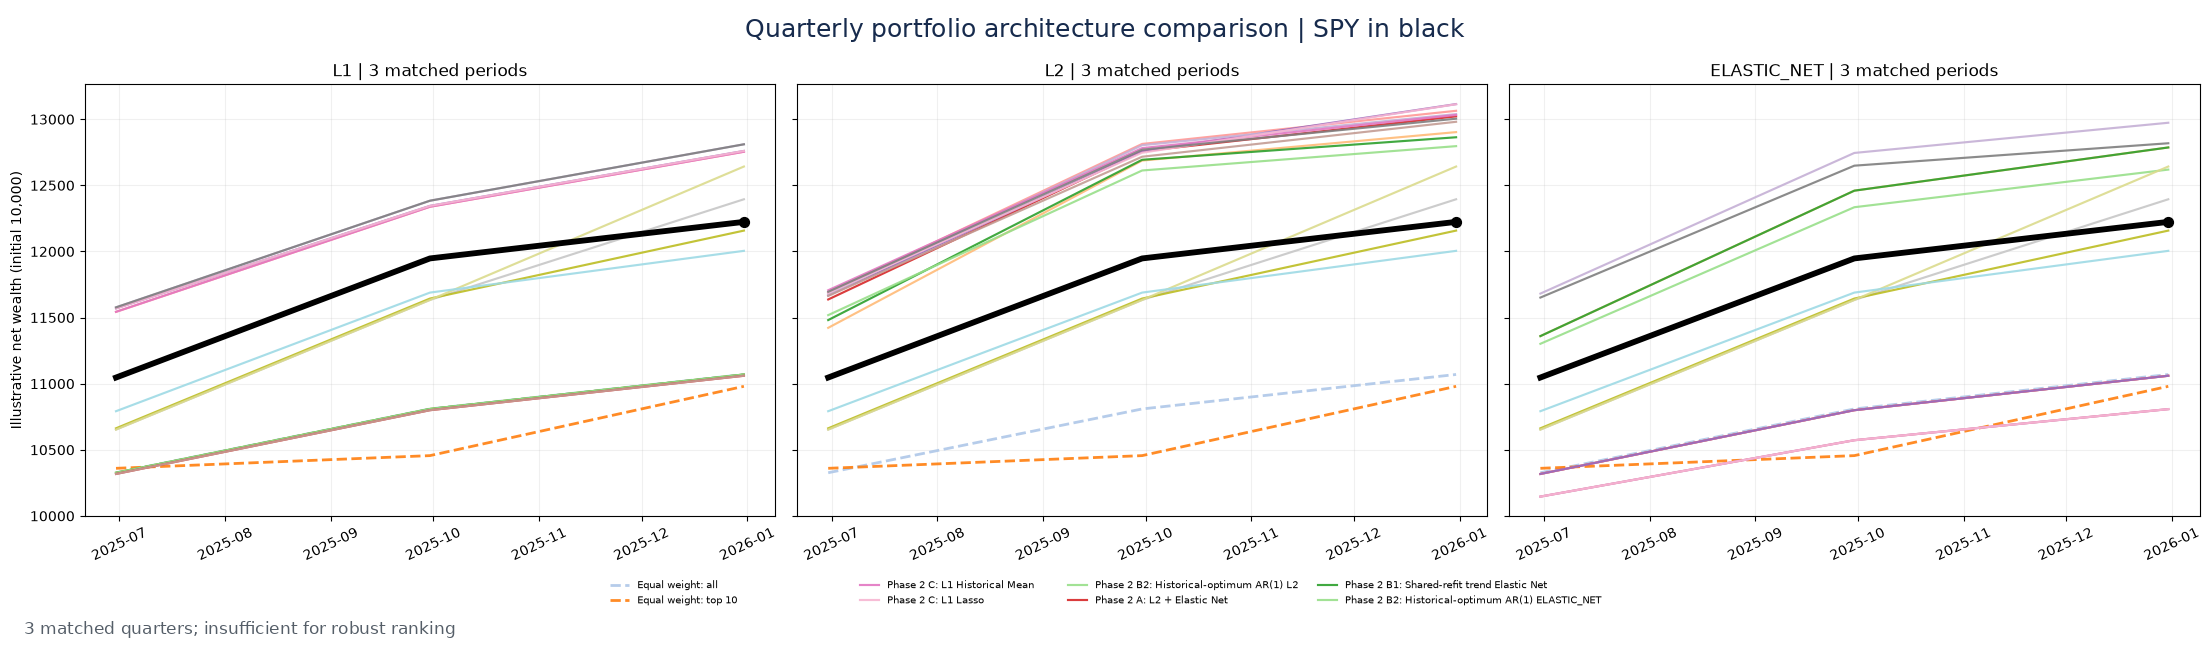

In [19]:
from IPython.display import Image, display
for label,filename in [('Portfolio policies — monthly','phase1_monthly_wealth.png'),('Portfolio policies — quarterly','phase1_quarterly_wealth.png'),('Forecast-informed allocations — monthly','phase2_monthly_wealth.png'),('Forecast-informed allocations — quarterly','phase2_quarterly_wealth.png')]:
    print(label)
    display(Image(filename=str(ROOT/'figures'/filename),width=1050))


## Forecast-informed allocation benchmark (separate evaluation cohort)

This cohort is descriptive and must not be ranked against the earlier policy cohort using unmatched starting dates.


In [20]:
cols=[c for c in ['frequency','approach','periods','ending_wealth','spy_wealth','max_drawdown'] if c in forecast.columns]
a=forecast[cols].copy()
if {'ending_wealth','spy_wealth'}.issubset(a.columns):
    a['wealth_vs_spy_pct']=100*(a.ending_wealth/a.spy_wealth-1)
display(a.sort_values(['frequency','ending_wealth'],ascending=[True,False]).round(3))


,frequency,approach,periods,ending_wealth,spy_wealth,max_drawdown,wealth_vs_spy_pct
0,monthly,Return-informed allocation with temporal adjus...,59,30086.900,18578.305,-0.214,61.946
1,monthly,Return-informed allocation,59,29915.110,18578.305,-0.216,61.022
2,monthly,Direct allocation policy,59,24668.317,18578.305,-0.258,32.780
3,monthly,Equal-weight,59,17757.126,18578.305,-0.197,-4.420
4,monthly,Factor-ranked equal-weight selection,59,17754.545,18578.305,-0.204,-4.434
6,quarterly,Return-informed allocation,3,13063.896,12223.874,0.000,6.872
5,quarterly,Return-informed allocation with temporal adjus...,3,13032.580,12223.874,0.000,6.616
7,quarterly,Direct allocation policy,3,12902.756,12223.874,0.000,5.554
8,quarterly,Equal-weight,3,11069.733,12223.874,0.000,-9.442
9,quarterly,Factor-ranked equal-weight selection,3,10980.184,12223.874,0.000,-10.174
